### Reading the ROI from the tiff file

In [1]:
from pathlib import Path
import re
import numpy as np
import tifffile

In [2]:
PATH = Path("~/Documents/annoloop_demo_images/clustering_images/ROI1_AllMarkers.tif").expanduser()

# ---- settings -------------------------------------------------------------------------------------------
# ROI in full-resolution pixels: rows Y0:Y1, columns X0:X1 (the whole image is 10325 x 9424)
Y0, Y1, X0, X1 = 4000, 5500, 4000, 5500
# the three markers shown in the ROI picture (exact channel names, see CHANNEL_NAMES below)
DAPI     = "DAPI C1 (DAPI C1)"
F480     = "F4_80 REA126 (PE C2)"
MEMBRANE = "Actin REAL650 (FITC C18)"
# ---------------------------------------------------------------------------------------------------------

with tifffile.TiffFile(PATH) as tf:
    CHANNEL_NAMES = re.findall(r'<Channel [^>]*Name="([^"]*)"', tf.ome_metadata)   # marker names stored in the OME metadata
    full_shape = tf.series[0].shape
    arr = np.stack([pg.asarray()[Y0:Y1, X0:X1] for pg in tf.pages])                # read only the ROI of every channel
print("whole image:", full_shape, "| ROI:", arr.shape, arr.dtype)
print(len(CHANNEL_NAMES), "channels")
for name in (DAPI, F480, MEMBRANE):
    assert name in CHANNEL_NAMES, f"{name!r} is not a channel name"

whole image: (33, 10325, 9424) | ROI: (33, 1500, 1500) uint16
33 channels


### Importing the ROI into SpatialData

In [3]:
import spatialdata as sd
from spatialdata.models import Image2DModel

In [4]:
img = Image2DModel.parse(
    arr,
    dims=("c", "y", "x"),            # TIFF axes are CYX
    c_coords=CHANNEL_NAMES,
    scale_factors=[2, 2, 2],
)

sdata = sd.SpatialData(images={"ROI1": img})
print(sdata)

SpatialData object
└── Images
      └── 'ROI1': DataTree[cyx] (33, 1500, 1500), (33, 750, 750), (33, 375, 375), (33, 187, 187)
with coordinate systems:
    ▸ 'global', with elements:
        ROI1 (Images)


### 1. The ROI: DAPI, F4/80 and a membrane marker
F4/80 red (denoised: blurred, haze subtracted), membrane marker green, DAPI blue.

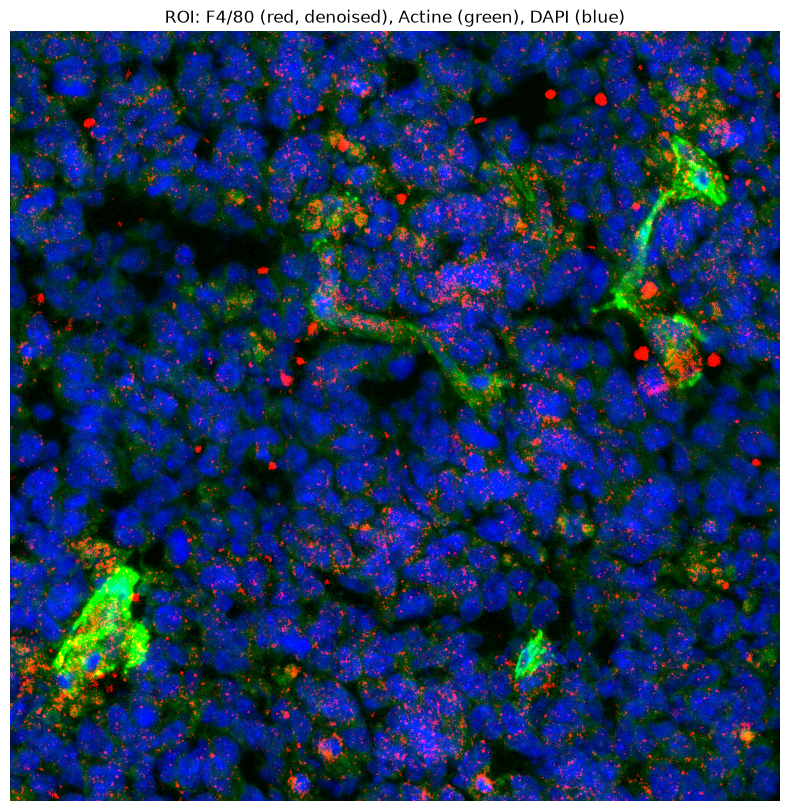

In [5]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

def norm(a, lo=1, hi=99.5):
    lo, hi = np.percentile(a, (lo, hi))
    return np.clip((a - lo) / (hi - lo), 0, 1)


rgb = np.dstack([norm(arr[CHANNEL_NAMES.index(F480)].astype(float), 90, 95),
                 norm(arr[CHANNEL_NAMES.index(MEMBRANE)].astype(float)),
                 norm(arr[CHANNEL_NAMES.index(DAPI)].astype(float))])

plt.figure(figsize=(10, 10)); plt.imshow(rgb); plt.axis("off")
plt.title("ROI: F4/80 (red, denoised), Actine (green), DAPI (blue)"); plt.show()

### 2. Pixel clustering: Harpy preprocessing + FlowSOM
Channels used for clustering exclude the three empty-cycle channels (FITC/PE/APC C0) and DAPI.

In [6]:
import dask
dask.config.set(scheduler="synchronous")   # FlowSOM uses numba, which crashes when dask threads call it concurrently

import harpy as hp

EXCLUDE = ["FITC (FITC C0)", "PE (PE C0)", "APC (APC C0)", "DAPI C1 (DAPI C1)"]
CHANNELS = [c for c in CHANNEL_NAMES if c not in EXCLUDE]
N_METACLUSTERS = 10

sdata = hp.im.pixel_clustering_preprocess(
    sdata,
    image_name="ROI1",
    output_image_name="ROI1_pre",
    channels=CHANNELS,
    overwrite=True,
)

sdata, fsom, mapping = hp.im.flowsom(
    sdata,
    image_name="ROI1_pre",
    output_cluster_labels_name="ROI1_som",
    output_metacluster_labels_name="ROI1_meta",
    channels=CHANNELS,
    fraction=0.1,                     # fraction of pixels used for training; prediction runs on all pixels
    n_clusters=N_METACLUSTERS,
    write_intermediate=False,      # sdata is not backed by a zarr store
    overwrite=True,
)

/Users/massimoz/Documents/cluster/.venv/lib/python3.14/site-packages/dask/array/core.py:5201: PerformanceWarning: Increasing number of chunks by factor of 29
  result = blockwise(
2026-11-23 15:05:55.307 +01:00 | INFO     | harpy.image._manager:add_element:47 - Writing results to element 'ROI1_pre'
2026-11-23 15:05:56.732 +01:00 | INFO     | harpy.image.pixel_clustering._clustering:flowsom:161 - Extracting random sample for FlowSOM training.
2026-11-23 15:05:56.769 +01:00 | INFO     | harpy.image.pixel_clustering._clustering:_sample_dask_array:398 - Start sampling
2026-11-23 15:05:58.794 +01:00 | INFO     | harpy.image.pixel_clustering._clustering:flowsom:219 - Start FlowSOM training.
2026-11-23 15:05:58.800 +01:00 | DEBUG    | flowsom.main:__init__:82 - Reading input.
2026-11-23 15:05:58.801 +01:00 | DEBUG    | flowsom.main:__init__:84 - Fitting model: clustering and metaclustering.
2026-11-23 15:06:03.955 +01:00 | DEBUG    | flowsom.main:__init__:86 - Updating derived values.
2026-11

### 2a. Elbow plot with FlowSOM
FlowSOM is run only once. It already gave every pixel to one of its 100 SOM nodes, so for each k we only group the 100 node centres into k metaclusters and compute the variance of the pixels around their metacluster centre.

In [15]:
level0 = lambda el: sd.get_pyramid_levels(el, n=0) if hasattr(el, "keys") else el

K_VALUES = range(2, 41)
N_PIXELS = 100_000

# 1. Pixel table (one row per pixel, one column per marker) and the SOM node of every pixel (0 = masked pixel)
pre_img = level0(sdata.images["ROI1_pre"]).values
pixel_table = pre_img.reshape(len(CHANNELS), -1).T
node_of_pixel = level0(sdata.labels["ROI1_som"]).values.ravel()

keep = (node_of_pixel != 0) & ~np.isnan(pixel_table).any(axis=1)
pixel_table, node_of_pixel = pixel_table[keep], node_of_pixel[keep]

rng = np.random.default_rng(0)
sample = rng.choice(len(pixel_table), size=min(N_PIXELS, len(pixel_table)), replace=False)
pixel_table, node_of_pixel = pixel_table[sample], node_of_pixel[sample]

# 2. The 100 SOM node centres. For each k, group them into k metaclusters
node_centres = fsom.model.codes
flowsom_variances = []
for k in K_VALUES:
    fsom.model.set_n_clusters(k)
    metacluster_of_node = fsom.model.metacluster_model.fit_predict(node_centres)
    metacluster_of_pixel =  metacluster_of_node[node_of_pixel - 1]                   # node numbers start at 1

    # variance = mean squared distance of a pixel to the centre of its metacluster
    total = 0
    for m in range(k):
        pixels = pixel_table[metacluster_of_pixel == m]
        if len(pixels) > 0:
            total += ((pixels - pixels.mean(axis=0)) ** 2).sum()
    flowsom_variances.append(total / len(pixel_table))
    print(f"k = {k}: variance = {flowsom_variances[-1]:.4f}")


k = 2: variance = 0.3684
k = 3: variance = 0.3653
k = 4: variance = 0.3621
k = 5: variance = 0.3588
k = 6: variance = 0.3576
k = 7: variance = 0.3504
k = 8: variance = 0.3491
k = 9: variance = 0.3329
k = 10: variance = 0.2749
k = 11: variance = 0.2676
k = 12: variance = 0.2666
k = 13: variance = 0.2657
k = 14: variance = 0.2646
k = 15: variance = 0.2546
k = 16: variance = 0.2443
k = 17: variance = 0.2372
k = 18: variance = 0.2260
k = 19: variance = 0.2252
k = 20: variance = 0.2243
k = 21: variance = 0.2196
k = 22: variance = 0.2179
k = 23: variance = 0.2165
k = 24: variance = 0.2158
k = 25: variance = 0.2140
k = 26: variance = 0.2129
k = 27: variance = 0.2108
k = 28: variance = 0.2095
k = 29: variance = 0.2081
k = 30: variance = 0.2008
k = 31: variance = 0.1996
k = 32: variance = 0.1964
k = 33: variance = 0.1948
k = 34: variance = 0.1941
k = 35: variance = 0.1933
k = 36: variance = 0.1927
k = 37: variance = 0.1920
k = 38: variance = 0.1910
k = 39: variance = 0.1891
k = 40: variance = 0

### 2b. Elbow plot with k-means (to compare with the FlowSOM elbow)
Plain k-means on the same preprocessed pixels, for every k. The y axis is the same as the FlowSOM elbow: mean squared distance of a pixel to the centre of its cluster. This does not use FlowSOM, so it needs only the clustering cell above.

In [8]:
from sklearn.cluster import KMeans

level0 = lambda el: sd.get_pyramid_levels(el, n=0) if hasattr(el, "keys") else el

K_VALUES = range(2, 41)
N_PIXELS = 100_000                    # k-means on a random sample of pixels, otherwise it is slow

# 1. Table of pixels: one row per pixel, one column per marker (masked pixels removed)
pre_img = level0(sdata.images["ROI1_pre"]).values
pixel_table = pre_img.reshape(len(CHANNELS), -1).T
masked = level0(sdata.labels["ROI1_meta"]).values.ravel() == 0
pixel_table = pixel_table[~masked]
pixel_table = pixel_table[~np.isnan(pixel_table).any(axis=1)]

rng = np.random.default_rng(0)
sample = pixel_table[rng.choice(len(pixel_table), size=min(N_PIXELS, len(pixel_table)), replace=False)]

# 2. Run k-means once for every k and keep the variance
variances = []
for k in K_VALUES:
    kmeans = KMeans(n_clusters=k, n_init=3, random_state=0).fit(sample)
    variances.append(kmeans.inertia_ / len(sample))                       # inertia = sum of squared distances to the centre
    print(f"k = {k}: variance = {variances[-1]:.4f}")


k = 2: variance = 0.3083
k = 3: variance = 0.2838
k = 4: variance = 0.2643
k = 5: variance = 0.2517
k = 6: variance = 0.2422
k = 7: variance = 0.2348
k = 8: variance = 0.2281
k = 9: variance = 0.2220
k = 10: variance = 0.2172
k = 11: variance = 0.2120
k = 12: variance = 0.2070
k = 13: variance = 0.2040
k = 14: variance = 0.2007
k = 15: variance = 0.1984
k = 16: variance = 0.1957
k = 17: variance = 0.1936
k = 18: variance = 0.1919
k = 19: variance = 0.1900
k = 20: variance = 0.1886
k = 21: variance = 0.1867
k = 22: variance = 0.1851
k = 23: variance = 0.1834
k = 24: variance = 0.1825
k = 25: variance = 0.1807
k = 26: variance = 0.1795
k = 27: variance = 0.1784
k = 28: variance = 0.1773
k = 29: variance = 0.1765
k = 30: variance = 0.1751
k = 31: variance = 0.1741
k = 32: variance = 0.1729
k = 33: variance = 0.1719
k = 34: variance = 0.1715
k = 35: variance = 0.1705
k = 36: variance = 0.1695
k = 37: variance = 0.1689
k = 38: variance = 0.1680
k = 39: variance = 0.1672
k = 40: variance = 0

### 2c. Both elbows together
Needs the two cells above.

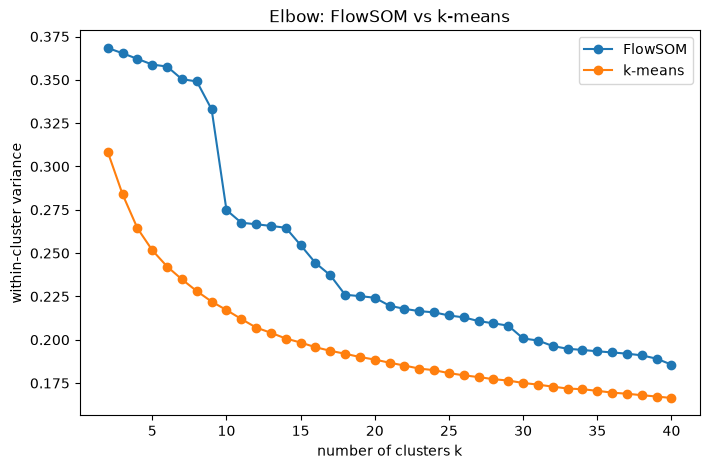

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(list(K_VALUES), flowsom_variances, "o-", label="FlowSOM")
plt.plot(list(K_VALUES), variances, "o-", label="k-means")
plt.xlabel("number of clusters k"); plt.ylabel("within-cluster variance")
plt.title("Elbow: FlowSOM vs k-means")
plt.legend()
plt.show()


### 3. The same ROI with the clusters
Every pixel coloured by its metacluster (black = masked pixels), with the metacluster numbers in the legend. With more than 20 metaclusters the colours repeat.

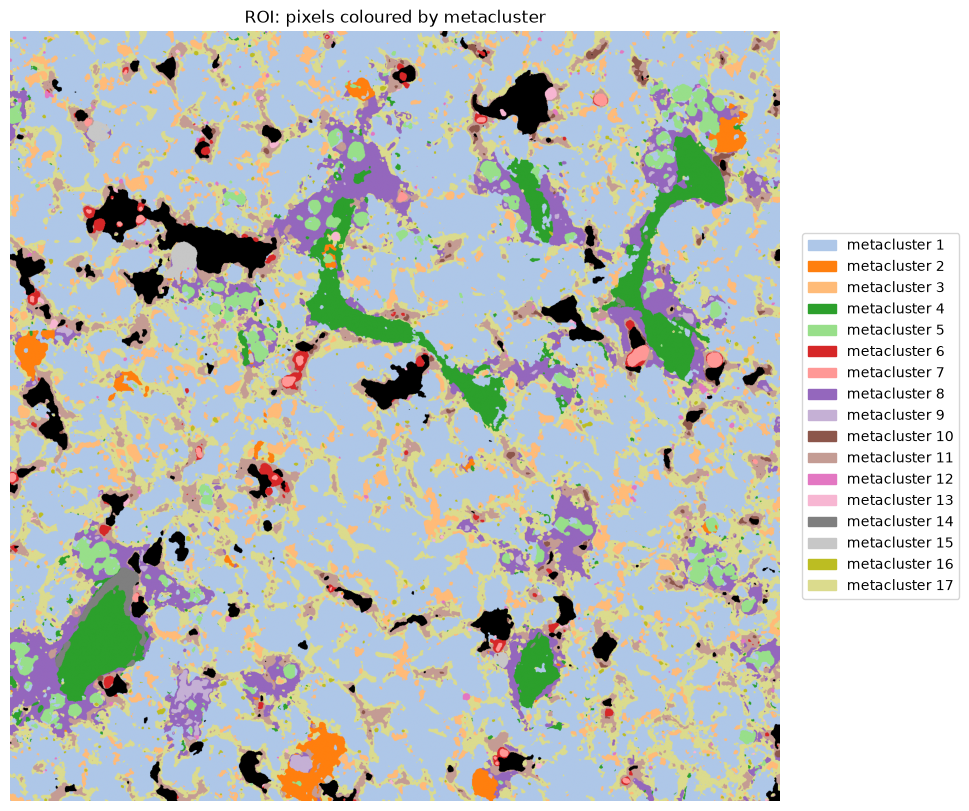

In [10]:
import matplotlib.patches as mpatches

level0 = lambda el: sd.get_pyramid_levels(el, n=0) if hasattr(el, "keys") else el

N_VIEW = 17          # number of metaclusters shown in the pictures (not linked to the elbow plots)

# 1. The metacluster of every pixel (0 = masked pixel).
#    FlowSOM already gave every pixel to one of its 100 SOM nodes, so we only regroup the node centres into N_VIEW metaclusters.
som_labels = level0(sdata.labels["ROI1_som"]).values
fsom.model.set_n_clusters(N_VIEW)
metacluster_of_node = fsom.model.metacluster_model.fit_predict(fsom.model.codes)
meta_of_pixel = metacluster_of_node[node_of_pixel - 1] + 1
lookup = np.concatenate([[0], metacluster_of_node + 1])                   # node number -> metacluster number (0 stays 0)
labels = lookup[som_labels]
cluster_ids = [i for i in np.unique(labels) if i != 0]

# 2. One colour per metacluster (tab20 has 20 colours, so ids above 20 would reuse colours)
palette = plt.get_cmap("tab20")

# 3. Paint every pixel with the colour of its metacluster. Masked pixels stay black.
picture = np.zeros((labels.shape[0], labels.shape[1], 3))
for cluster_id in cluster_ids:
    picture[labels == cluster_id] = palette(cluster_id % 20)[:3]

legend = [mpatches.Patch(color=palette(i % 20), label=f"metacluster {i}") for i in cluster_ids]

plt.figure(figsize=(12, 10))
plt.imshow(picture)
plt.legend(handles=legend, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.axis("off")
plt.title("ROI: pixels coloured by metacluster")
plt.show()

### 3b. The image next to the clusters
The ROI picture and the cluster map side by side, with the same grid on both to compare the same spot. Needs `rgb` (ROI picture cell) and `picture`, `legend` (the cell above).

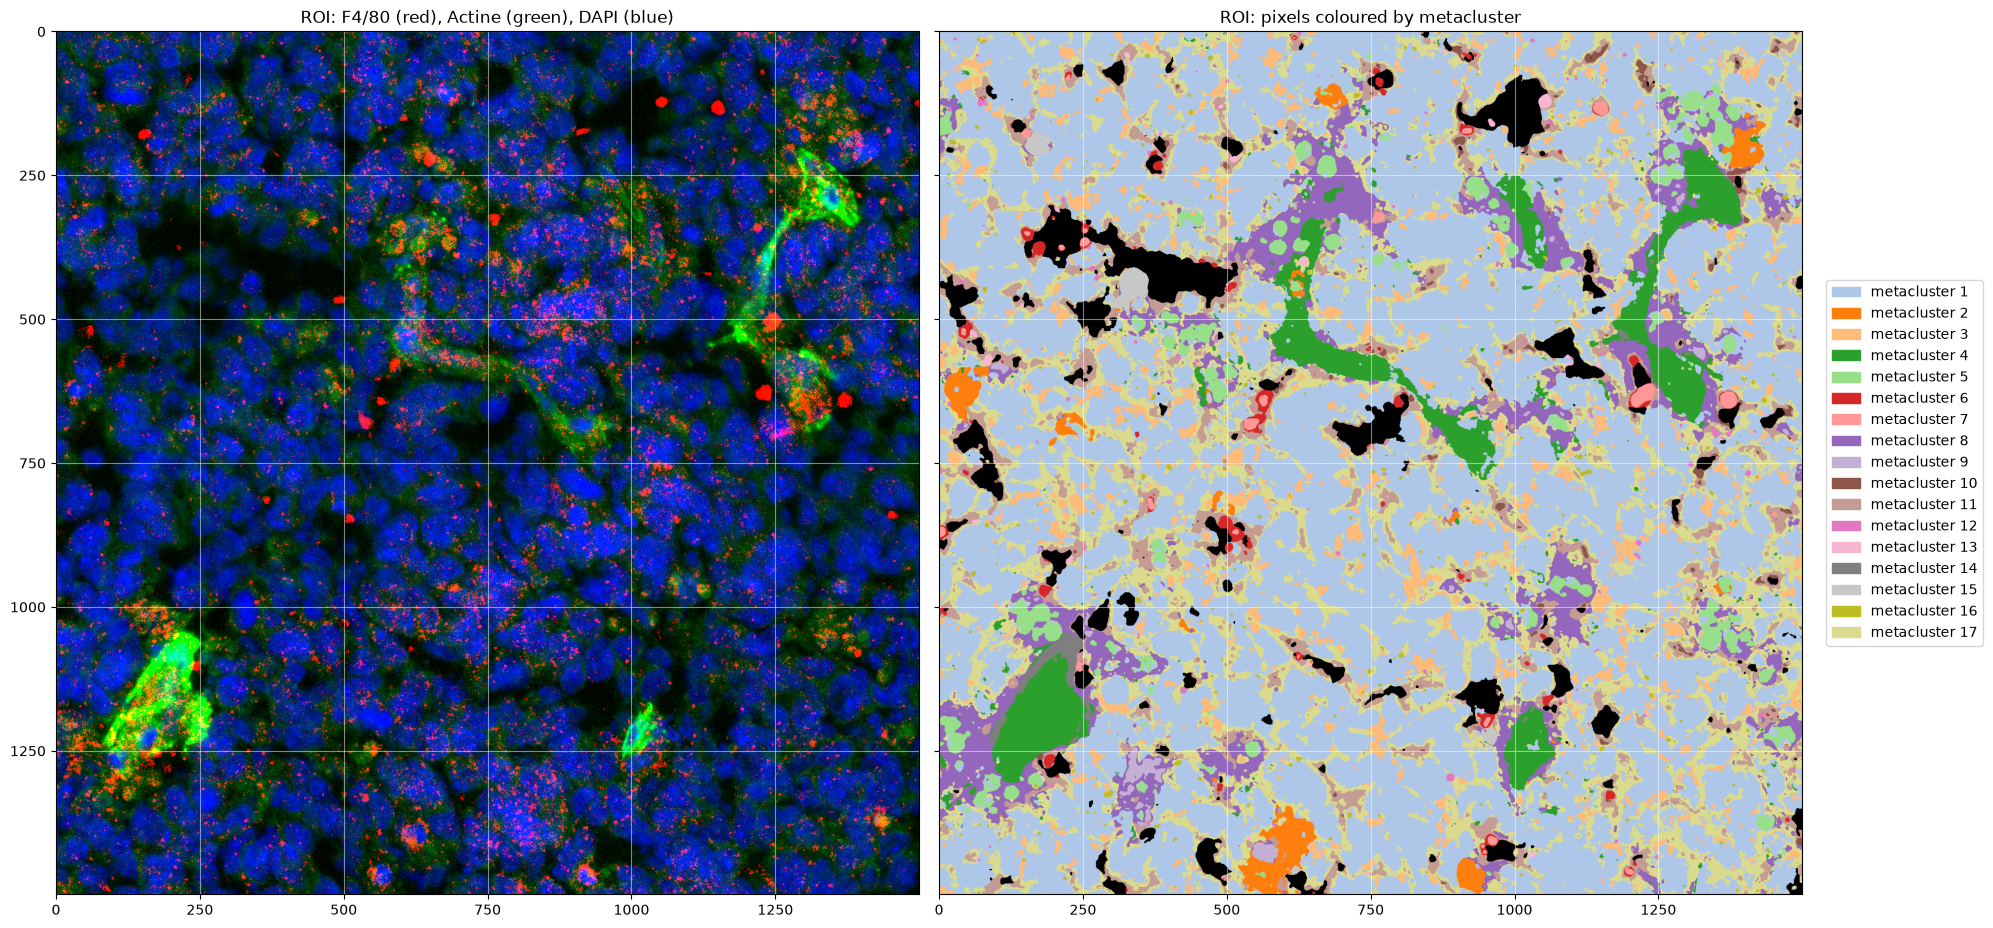

In [11]:
def clusters_picture(ids):
    if len(ids) == 0:
        ids = cluster_ids
    picture = np.zeros_like(rgb)
    for cluster_id in ids:
        picture[labels == cluster_id] = palette(cluster_id % 20)[:3]
    return picture

GRID_STEP = 250

fig, axes = plt.subplots(1, 2, figsize=(20, 10), sharex=True, sharey=True)    # sharex/sharey: zooming one zooms both

axes[0].imshow(rgb)
axes[0].set_title("ROI: F4/80 (red), Actine (green), DAPI (blue)")

axes[1].imshow(clusters_picture([]))
axes[1].set_title("ROI: pixels coloured by metacluster")
axes[1].legend(handles=legend, loc="center left", bbox_to_anchor=(1.02, 0.5))

for ax in axes:
    ax.set_xticks(range(0, rgb.shape[1], GRID_STEP))
    ax.set_yticks(range(0, rgb.shape[0], GRID_STEP))
    ax.grid(color="white", alpha=0.5, linewidth=0.8)
plt.tight_layout()
plt.show()


### 4. Heatmap: signal per metacluster
Markers are rows, metaclusters are columns (z-scored mean signal). The coloured strip is the metacluster colour used in the picture above.

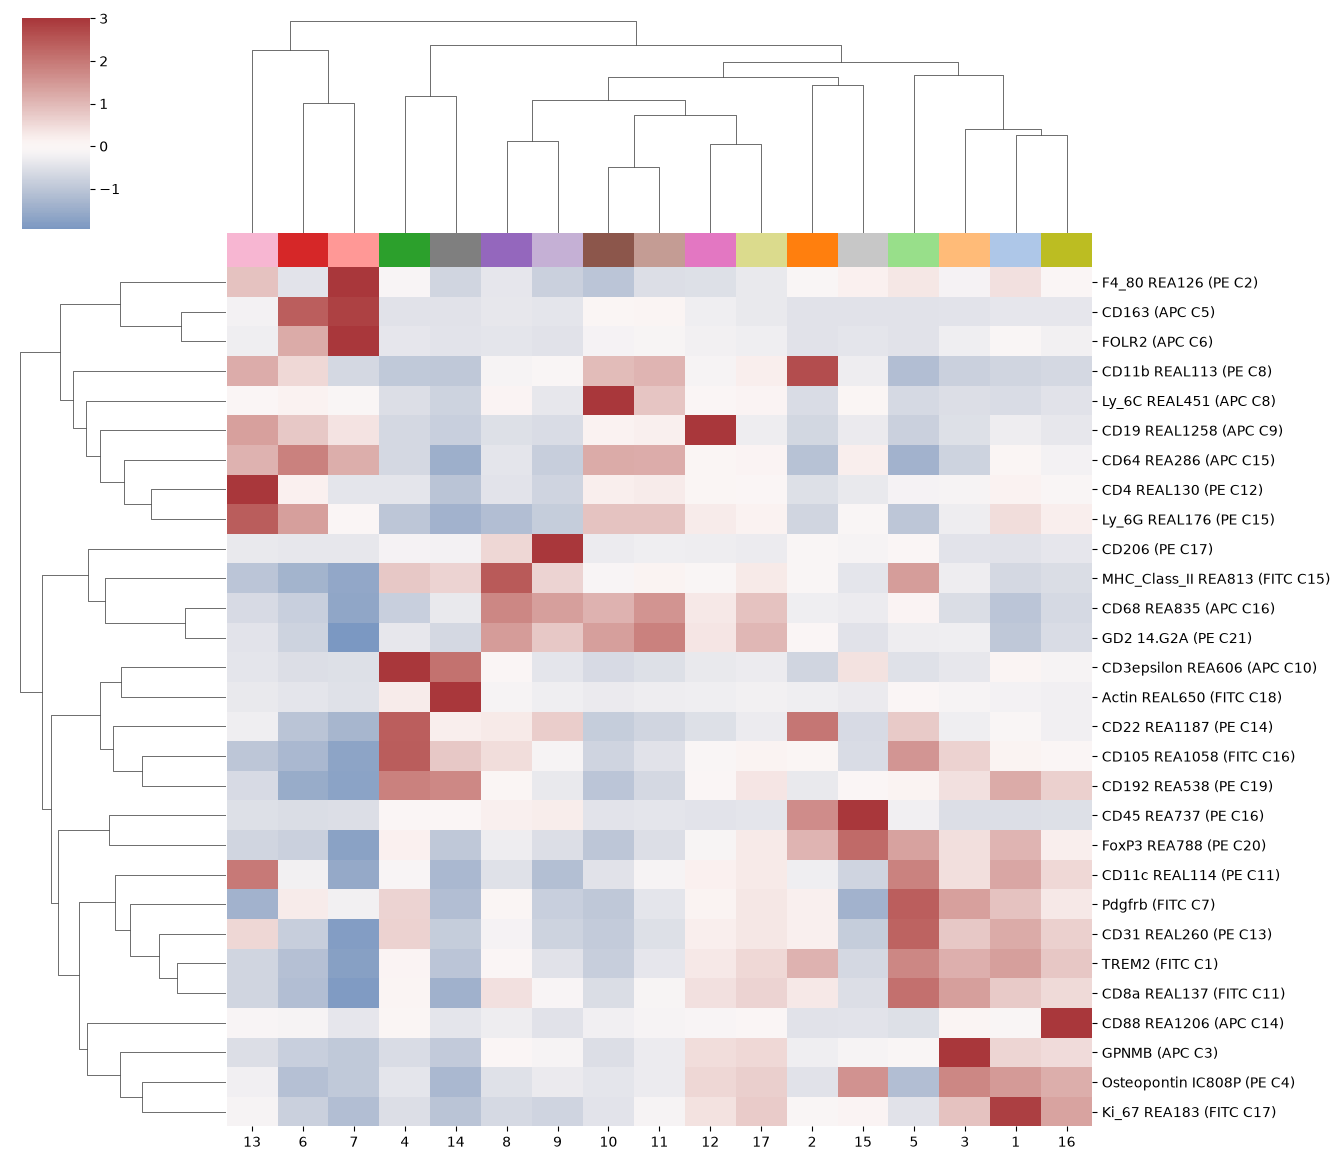

In [12]:
import pandas as pd
import seaborn as sns

pre_img = level0(sdata.images["ROI1_pre"]).values
means = pd.DataFrame(pre_img.reshape(len(CHANNELS), -1).T, columns=CHANNELS).groupby(labels.ravel()).mean()
means = means.drop(index=0, errors="ignore")
z = ((means - means.mean()) / means.std()).clip(-3, 3)                           # z-score each marker across metaclusters (clipped for readability)

pal = sns.color_palette("tab20", 20)
sns.clustermap(z.T, cmap="vlag", center=0, col_colors=[pal[i % 20] for i in z.index],
               figsize=(0.5 * len(z) + 5, 0.3 * len(CHANNELS) + 3))
plt.show()

## 5. Plot the variance in the clusters

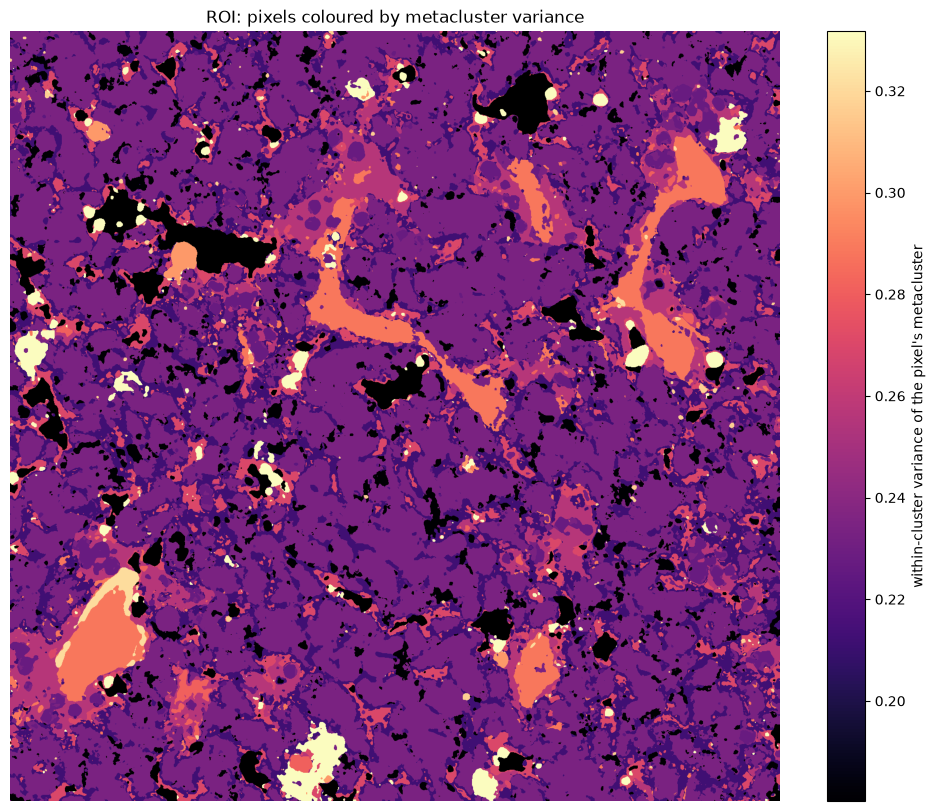

In [13]:
# Colour every pixel by the within-cluster variance of the metacluster it belongs to
# uses `labels` (cell 17: metacluster of every pixel, 0 = masked) and `pre_img` (preprocessed image)
px = pre_img.reshape(len(CHANNELS), -1).T
lab = labels.ravel()
ok = (lab != 0) & ~np.isnan(px).any(axis=1)

cluster_variance = {}
for c in np.unique(lab[ok]):
    p = px[ok & (lab == c)]
    cluster_variance[c] = ((p - p.mean(axis=0)) ** 2).sum(axis=1).mean()

variance_map = np.full(lab.shape, np.nan)
for c, v in cluster_variance.items():
    variance_map[ok & (lab == c)] = v
variance_map = variance_map.reshape(labels.shape)

cmap = plt.get_cmap("magma").copy(); cmap.set_bad("black")
plt.figure(figsize=(12, 10))
plt.imshow(variance_map, cmap=cmap, vmax=np.nanpercentile(variance_map, 99))
plt.colorbar(label="within-cluster variance of the pixel's metacluster", fraction=0.046)
plt.axis("off"); plt.title("ROI: pixels coloured by metacluster variance")
plt.show()


In [19]:
%gui qt
import napari
from napari.utils.colormaps import DirectLabelColormap
from matplotlib.colors import to_hex
from IPython.display import HTML, display

viewer = napari.Viewer()

# only the clusters: one labels layer per cluster, fully opaque, on a black background
for c in cluster_ids:
    colors = {None: "transparent", 0: "transparent", c: palette(c % 20)}
    viewer.add_labels((labels * (labels == c)).astype(np.uint16), name=f"cluster {c}",
                      colormap=DirectLabelColormap(color_dict=colors), opacity=1.0)
    
# marker channels (DAPI blue, F4/80 red, actin green), added on top of the clusters
for name, cmap in [(DAPI, "blue"), (F480, "red"), (MEMBRANE, "green")]:
    ch = arr[CHANNEL_NAMES.index(name)]
    viewer.add_image(ch, name=name, colormap=cmap, blending="additive",
                     contrast_limits=tuple(np.percentile(ch, (1, 99.5))))

# colour key: which colour is which cluster (same colours as in napari and in the cluster picture)
display(HTML(" ".join(
    f'<span style="display:inline-block;width:18px;height:14px;border:1px solid #888;'
    f'background:{to_hex(palette(c % 20))};vertical-align:middle"></span> cluster {c}&nbsp;&nbsp;'
    for c in cluster_ids)))

TypeError: Only integer types are supported for Labels layers, but data contains float64.